# Customer Churn Analysis

This notebook works through a full analysis in four parts:

- **A.** Exploratory data analysis
- **B.** Data preprocessing
- **C.** Hypothesis testing
- **D.** A predictive model

**Data:** IBM Telco Customer Churn dataset (7,043 customers, 33 columns), the version that includes CLTV and Churn Reason.

# Part A: Exploratory Data Analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = 'data/Telco_customer_churn.xlsx'
df = pd.read_excel(DATA_PATH)
df.head()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   object 
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   object 
 3   State              7043 non-null   object 
 4   City               7043 non-null   object 
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   object 
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   object 
 10  Senior Citizen     7043 non-null   object 
 11  Partner            7043 non-null   object 
 12  Dependents         7043 non-null   object 
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   object 
 15  Multiple Lines     7043 non-null   object 
 16  Internet Service   7043 

`Total Charges` is stored as text because some rows contain blanks. The next cell converts it to a number, which turns those blanks into missing values that Part B deals with.

In [3]:
df['Total Charges'] = pd.to_numeric(df['Total Charges'], errors='coerce')
df['Total Charges'].isna().sum()

11

In [4]:
df.describe().drop('count')

,Count,Zip Code,Latitude,Longitude,Tenure Months,Monthly Charges,Total Charges,Churn Value,Churn Score,CLTV
mean,1.0,93521.964646,36.282441,-119.798880,32.371149,64.761692,2283.300441,0.265370,58.699418,4400.295755
std,0.0,1865.794555,2.455723,2.157889,24.559481,30.090047,2266.771362,0.441561,21.525131,1183.057152
min,1.0,90001.000000,32.555828,-124.301372,0.000000,18.250000,18.800000,0.000000,5.000000,2003.000000
25%,1.0,92102.000000,34.030915,-121.815412,9.000000,35.500000,401.450000,0.000000,40.000000,3469.000000
50%,1.0,93552.000000,36.391777,-119.730885,29.000000,70.350000,1397.475000,0.000000,61.000000,4527.000000
75%,1.0,95351.000000,38.224869,-118.043237,55.000000,89.850000,3794.737500,1.000000,75.000000,5380.500000
max,1.0,96161.000000,41.962127,-114.192901,72.000000,118.750000,8684.800000,1.000000,100.000000,6500.000000


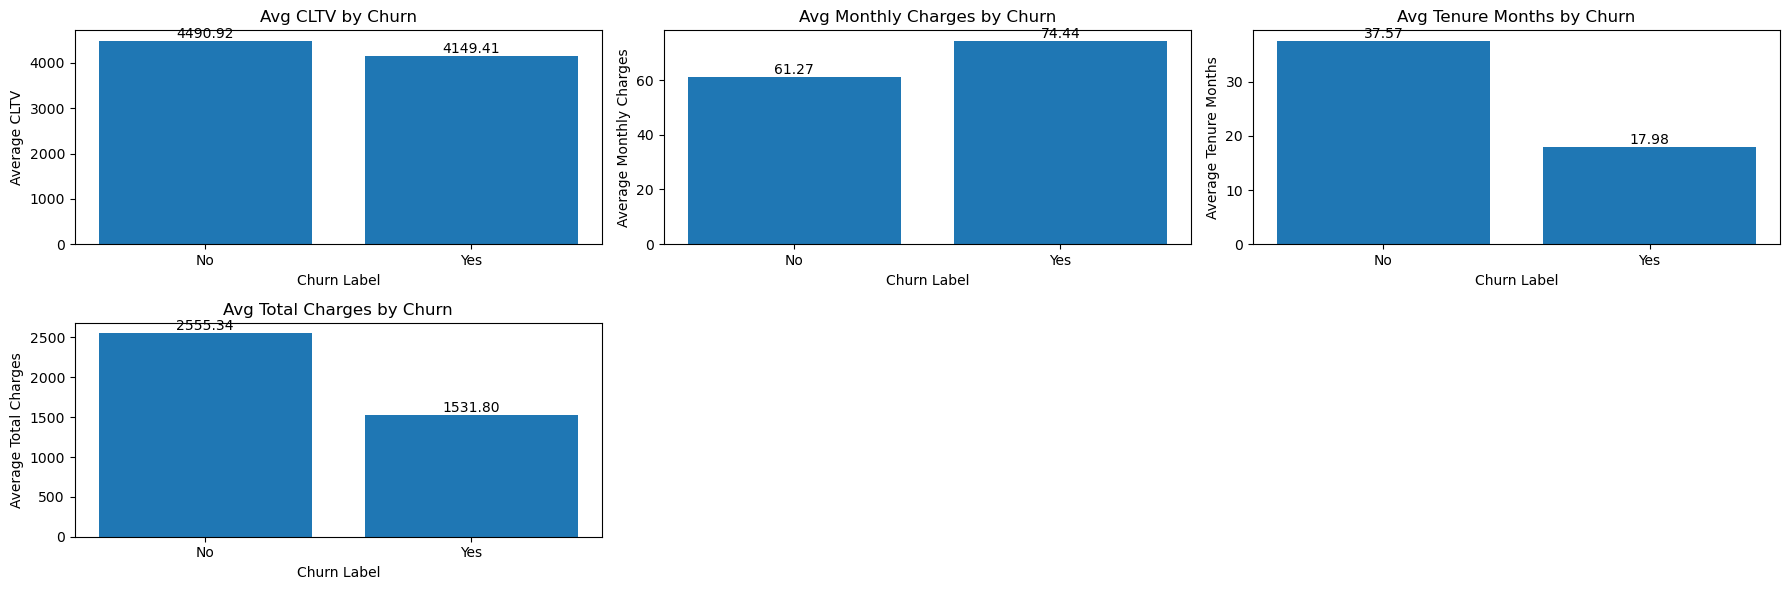

In [5]:
exclude_cols = ['Churn Value', 'Latitude', 'Longitude', 'Churn Score', 'Count', 'Zip Code']
num_features = df.select_dtypes(include=[np.number]).columns.difference(exclude_cols)
churn_groups = df.groupby('Churn Label')[num_features].mean()

fig, axs = plt.subplots(nrows=int(np.ceil(len(num_features) / 3)), ncols=3, figsize=(18, 6))
axs = axs.flatten()
for i, col in enumerate(num_features):
    axs[i].bar(churn_groups.index.astype(str), churn_groups[col])
    axs[i].set_title(f'Avg {col} by Churn')
    axs[i].set_xlabel('Churn Label')
    axs[i].set_ylabel(f'Average {col}')
    for j, val in enumerate(churn_groups[col]):
        axs[i].text(j, val, f'{val:.2f}', ha='center', va='bottom')
for ax in axs[len(num_features):]:
    ax.axis('off')
plt.tight_layout()
plt.show()

### Insights from Tenure Months, Monthly Charges and CLTV

Each bar plot above shows the average of one numeric column for customers who churned and customers who stayed.

1. **Longer-tenured customers are less likely to churn.** Customers who stayed have an average tenure of 37.57 months, against 17.98 months for those who churned.
2. **Customers with higher monthly charges are more likely to churn.** Churned customers pay 74.44 a month on average, against 61.27 for those who stayed.
3. **Customers who stay are worth more.** CLTV (Customer Lifetime Value) estimates the total revenue a customer is expected to bring in. It is higher on average for customers who did not churn, so keeping customers matters for long-term revenue.

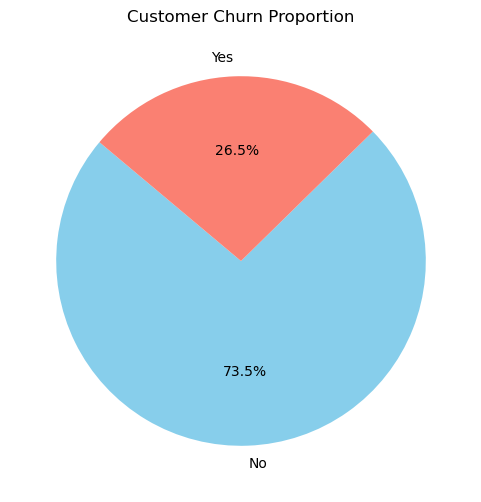

In [6]:
counts = df['Churn Label'].value_counts()
plt.figure(figsize=(6, 6))
plt.pie(counts.values, labels=counts.index, autopct='%1.1f%%', startangle=140,
        colors=['skyblue', 'salmon'])
plt.title('Customer Churn Proportion')
plt.show()

About 26.5% of customers churned. That class imbalance affects how the model is trained and evaluated in Part D.

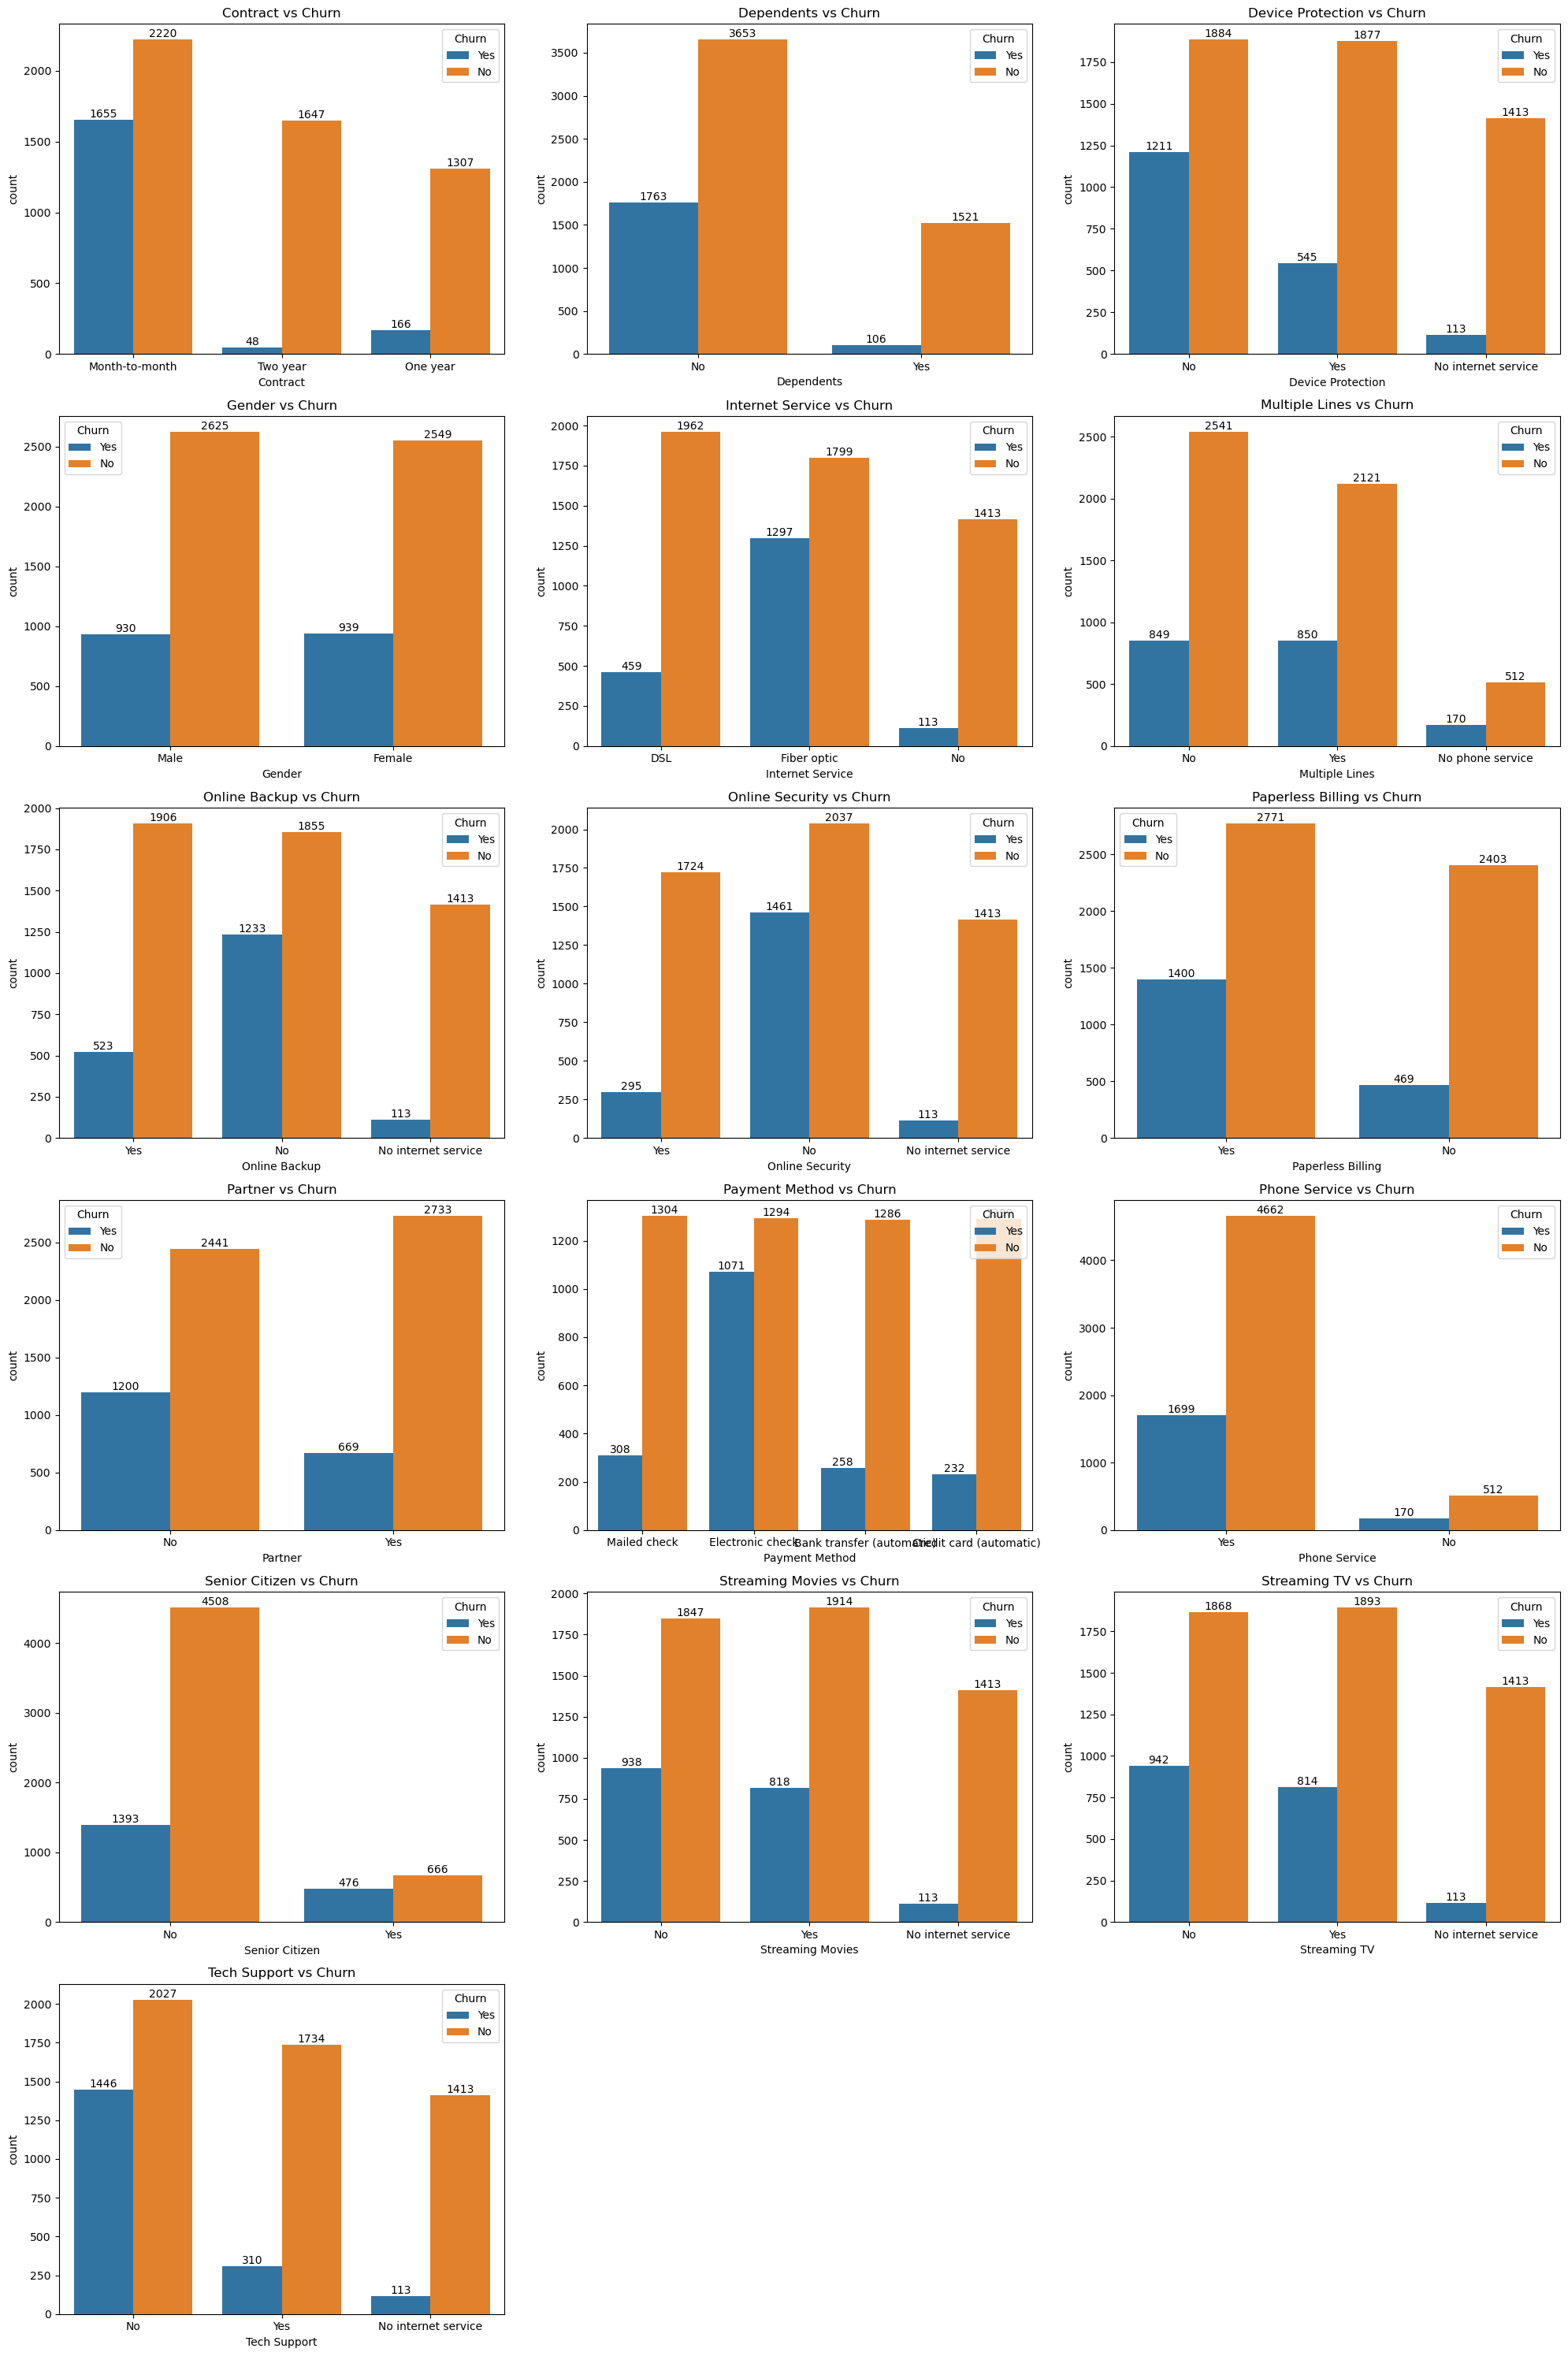

In [7]:
exclude_cat_cols = ['Churn Reason', 'City', 'Lat Long', 'CustomerID', 'Country', 'State', 'Churn Label']
cat_cols = df.select_dtypes(include=['object', 'string']).columns.difference(exclude_cat_cols)
n_cols = 3
n_rows = int(np.ceil(len(cat_cols) / n_cols))

fig, axs = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 5))
axs = axs.flatten()
for i, col in enumerate(cat_cols):
    sns.countplot(data=df, x=col, hue='Churn Label', ax=axs[i])
    axs[i].set_title(f'{col} vs Churn')
    for container in axs[i].containers:
        axs[i].bar_label(container)
    axs[i].legend(title='Churn')
for ax in axs[len(cat_cols):]:
    ax.axis('off')
plt.tight_layout()
plt.show()

In [8]:
churn_reason_df = (df['Churn Reason'].value_counts()
                   .rename_axis('Churn Reason').reset_index(name='Count'))
churn_reason_df['Percentage'] = (churn_reason_df['Count'] / churn_reason_df['Count'].sum() * 100).round(2)
churn_reason_df

,Churn Reason,Count,Percentage
0,Attitude of support person,192,10.27
1,Competitor offered higher download speeds,189,10.11
2,Competitor offered more data,162,8.67
3,Don't know,154,8.24
4,Competitor made better offer,140,7.49
5,Attitude of service provider,135,7.22
6,Competitor had better devices,130,6.96
7,Network reliability,103,5.51
8,Product dissatisfaction,102,5.46
9,Price too high,98,5.24


### Top 3 churn drivers and proposed interventions

1. **Attitude of support person (10.27%)**
   - Short term: train support staff in empathy and communication, and collect customer feedback after support contacts.
   - Long term: monitor support quality, coach staff, and reward excellent service.

2. **Competitor offered higher download speeds (10.11%)**
   - Short term: offer speed-upgrade trials to dissatisfied customers.
   - Long term: invest in network infrastructure and introduce speed guarantees.

3. **Competitor offered more data (8.67%)**
   - Short term: offer bonus data or promotional bundles.
   - Long term: launch competitive data plans with data rollover.

# Part B: Data Preprocessing

In [9]:
missing = df.isnull().sum()
missing[missing > 0].sort_values(ascending=False)

Churn Reason     5174
Total Charges      11
dtype: int64

`Churn Reason` is missing only for customers who did not churn, which is expected, and it is not used as a model feature.

Before filling the 11 missing `Total Charges` values, the next cell checks *why* they are missing.

In [10]:
df.loc[df['Total Charges'].isna(), 'Tenure Months'].value_counts()

Tenure Months
0    11
Name: count, dtype: int64

Every customer with a missing `Total Charges` has a tenure of 0 months. They are new customers who have not been billed yet, so the correct value is **0**, not the mode or the mean.

In [11]:
df['Total Charges'] = df['Total Charges'].fillna(0)
df['Total Charges'].isna().sum()

0

Skewness:
 Total Charges      0.963235
Tenure Months      0.239540
Monthly Charges   -0.220524
CLTV              -0.311602
dtype: float64


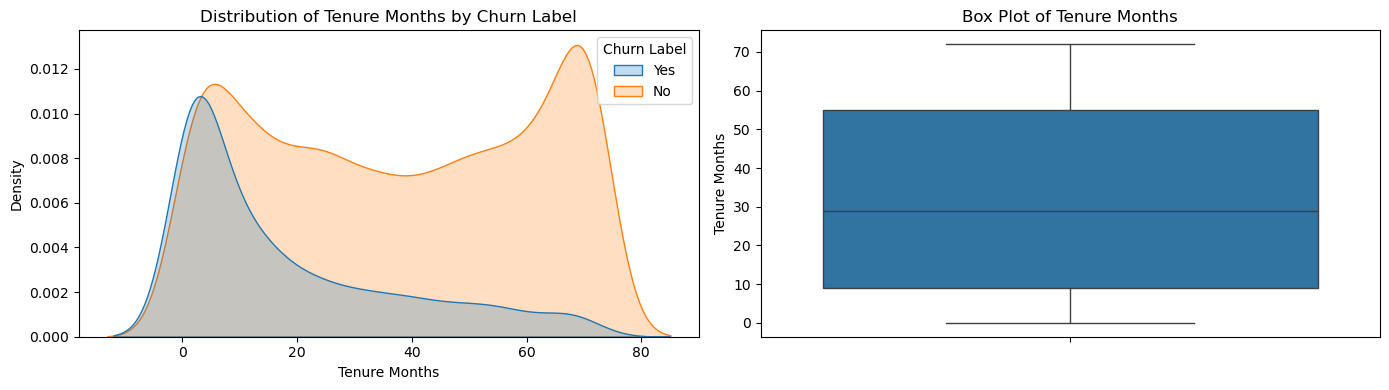

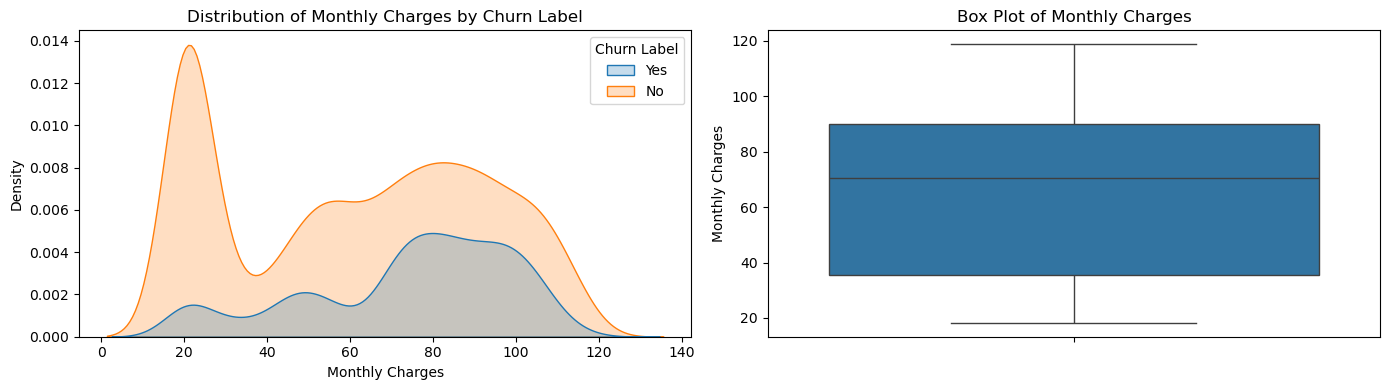

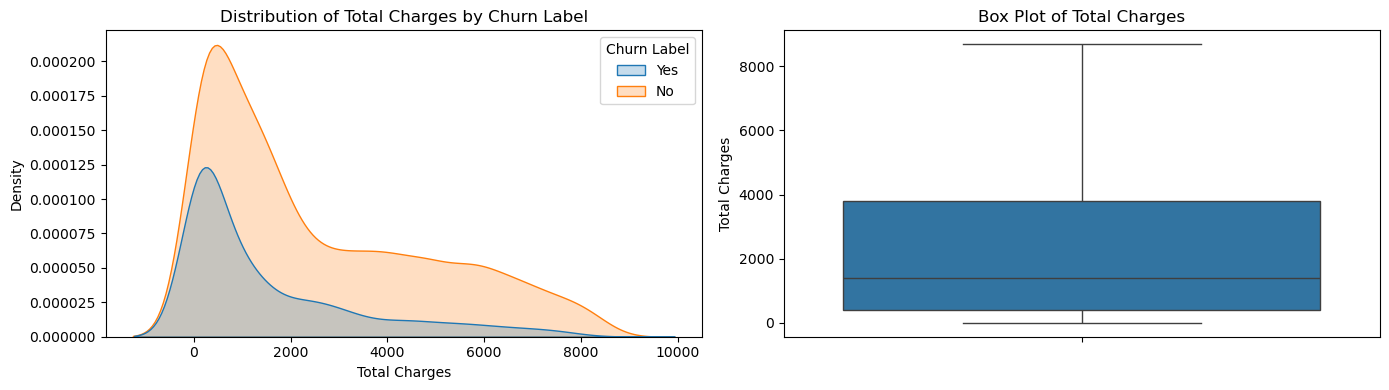

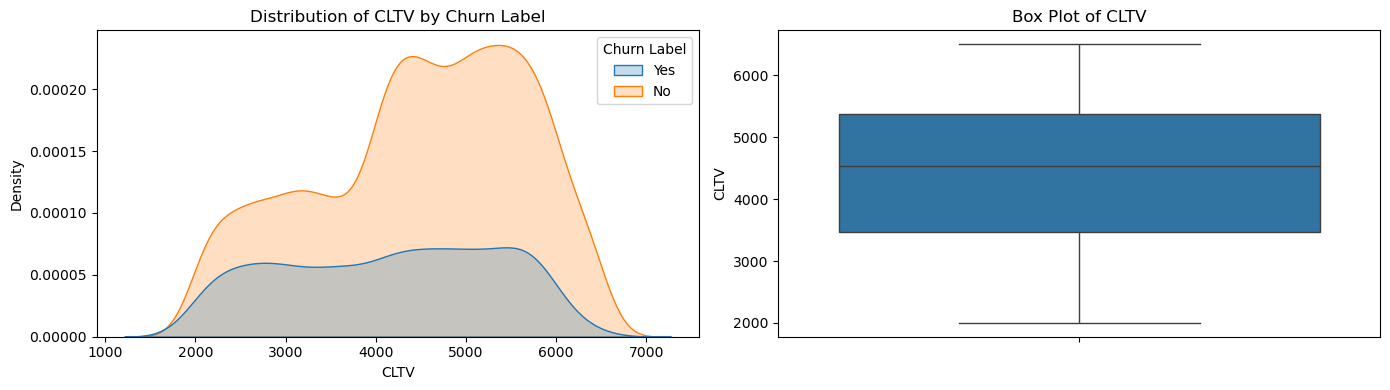

In [12]:
num_cols = ['Tenure Months', 'Monthly Charges', 'Total Charges', 'CLTV']

skewness = df[num_cols].skew().sort_values(ascending=False)
print('Skewness:\n', skewness)

for col in num_cols:
    fig, axs = plt.subplots(1, 2, figsize=(14, 4))
    sns.kdeplot(data=df, x=col, hue='Churn Label', fill=True, ax=axs[0])
    axs[0].set_title(f'Distribution of {col} by Churn Label')
    sns.boxplot(data=df, y=col, ax=axs[1])
    axs[1].set_title(f'Box Plot of {col}')
    plt.tight_layout()
    plt.show()

### Outliers and skew

The box plots show no points beyond the whiskers for any of the four numeric features, so no rows are removed as outliers.

`Total Charges` is right-skewed (skewness 0.96). It is not transformed because it is excluded from the model in Part D, where the reason is explained. The other three features are close to symmetric (|skew| < 0.35).

# Part C: Hypothesis Testing

Chi-square tests of independence between churn and three customer attributes.
For each test, H0 is that the attribute and churn are independent. The significance level is 0.05.

In [13]:
from scipy.stats import chi2_contingency

for col in ['Phone Service', 'Contract', 'Senior Citizen']:
    table = pd.crosstab(df[col], df['Churn Label'])
    chi2, p, dof, expected = chi2_contingency(table)
    print(f'{col} vs Churn  ->  Chi2 = {chi2:.2f}, dof = {dof}, p-value = {p:.3g}')

Phone Service vs Churn  ->  Chi2 = 0.92, dof = 1, p-value = 0.339
Contract vs Churn  ->  Chi2 = 1184.60, dof = 2, p-value = 5.86e-258
Senior Citizen vs Churn  ->  Chi2 = 159.43, dof = 1, p-value = 1.51e-36


### Management conclusions

1. **Phone Service vs Churn**: Chi2 = 0.92, p = 0.339 (> 0.05).
   - *Conclusion:* We fail to reject H0. There is no statistically significant relationship between having phone service and churn.
   - *Implication:* Targeting retention efforts by phone service status is unlikely to be effective.

2. **Contract Type vs Churn**: Chi2 = 1184.60, p ≈ 5.9e-258.
   - *Conclusion:* We reject H0. Contract type is strongly associated with churn.
   - *Implication:* Contract terms are a key lever for retention, for example incentives to move month-to-month customers onto longer contracts.

3. **Senior Citizen vs Churn**: Chi2 = 159.43, p ≈ 1.5e-36.
   - *Conclusion:* We reject H0. Senior citizen status is significantly associated with churn.
   - *Implication:* Retention strategies could be tailored to senior customers' specific needs.

# Part D: Predictive Model Development

**Feature selection.** The following columns are excluded from the features:

- `CustomerID`: an identifier with no predictive meaning.
- `Count`, `Country`, `State`: the same value in every row.
- `City`, `Zip Code`, `Lat Long`, `Latitude`, `Longitude`: one-hot encoding `City` alone would add more than 1,100 sparse columns for about 7,000 rows, which invites overfitting.
- `Churn Label`, `Churn Value`, `Churn Reason`, `Churn Score`: these are the target, or are derived from it, so including them would leak the answer into the model.
- `Total Charges`: this is roughly `Tenure Months` × `Monthly Charges`, so it duplicates information already in the model. In an earlier run with it included, its coefficient swamped every other feature, which made the coefficients hard to interpret.

In [14]:
from sklearn.model_selection import train_test_split

drop_cols = ['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code',
             'Lat Long', 'Latitude', 'Longitude',
             'Churn Label', 'Churn Value', 'Churn Reason', 'Churn Score',
             'Total Charges']

X = df.drop(columns=drop_cols)
y = df['Churn Value']  # 1 = churned, 0 = stayed

numeric_features = ['Tenure Months', 'Monthly Charges', 'CLTV']
categorical_features = [c for c in X.columns if c not in numeric_features]

# 70% train, 30% test, keeping the churn ratio the same in both
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)
print('Training set:', X_train.shape)
print('Test set:    ', X_test.shape)

Training set: (4930, 19)
Test set:     (2113, 19)


**Pipeline.** Scaling and one-hot encoding sit inside a scikit-learn `Pipeline`, so they are fitted on the training data only, including within each cross-validation fold. This prevents information from the test set leaking into training.

**Tuning.** Only about 26.5% of customers churn, so accuracy is a misleading target: a model that predicts "stayed" for everyone already scores 73.5%. The grid search optimises **F1 for the churn class** instead, and also tries `class_weight='balanced'`, which makes errors on churners count more during training.

In [15]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

preprocess = ColumnTransformer([
    ('num', MinMaxScaler(), numeric_features),
    ('cat', OneHotEncoder(drop='if_binary', handle_unknown='ignore'), categorical_features),
])

pipe = Pipeline([
    ('prep', preprocess),
    ('model', LogisticRegression(solver='liblinear', max_iter=1000, random_state=42)),
])

param_grid = {
    'model__penalty': ['l1', 'l2'],
    'model__C': [0.01, 0.1, 1, 10],
    'model__class_weight': [None, 'balanced'],
}

grid = GridSearchCV(pipe, param_grid, cv=5, scoring='f1', n_jobs=-1)
grid.fit(X_train, y_train)

best_model = grid.best_estimator_
print('Best hyperparameters:', grid.best_params_)
print(f'Best cross-validated F1: {grid.best_score_:.3f}')

Best hyperparameters: {'model__C': 10, 'model__class_weight': 'balanced', 'model__penalty': 'l2'}
Best cross-validated F1: 0.643


In [16]:
from sklearn.metrics import classification_report, roc_auc_score, average_precision_score

y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred, target_names=['Stayed', 'Churned']))
print(f'ROC-AUC: {roc_auc_score(y_test, y_prob):.3f}')
print(f'PR-AUC:  {average_precision_score(y_test, y_prob):.3f}  (baseline = churn rate = {y_test.mean():.3f})')

              precision    recall  f1-score   support

      Stayed       0.90      0.74      0.81      1552
     Churned       0.52      0.78      0.62       561

    accuracy                           0.75      2113
   macro avg       0.71      0.76      0.72      2113
weighted avg       0.80      0.75      0.76      2113

ROC-AUC: 0.852
PR-AUC:  0.651  (baseline = churn rate = 0.265)


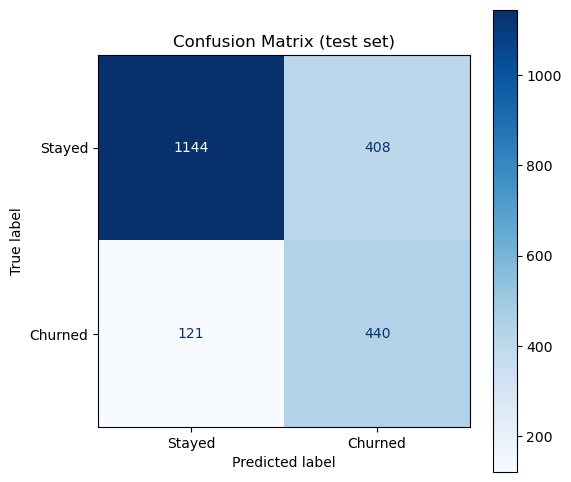

TP = 440, FP = 408, TN = 1144, FN = 121
Churn recall:    78.43%  (share of actual churners the model catches)
Churn precision: 51.89%  (share of flagged customers who actually churn)


In [17]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay(cm, display_labels=['Stayed', 'Churned']).plot(ax=ax, cmap=plt.cm.Blues)
plt.title('Confusion Matrix (test set)')
plt.show()

print(f'TP = {tp}, FP = {fp}, TN = {tn}, FN = {fn}')
print(f'Churn recall:    {tp / (tp + fn):.2%}  (share of actual churners the model catches)')
print(f'Churn precision: {tp / (tp + fp):.2%}  (share of flagged customers who actually churn)')

### Confusion matrix interpretation

The **positive class is Churned**. For a retention team, the most important number is **churn recall**: the share of customers who will actually leave that the model flags in time to intervene.

- The model catches **78.43%** of churners (TP = 440) and misses **21.57%** of them (121).
- Of the customers it flags, **51.89%** actually churn. The other **48.11%** (408) would receive a retention offer they didn't need.

There is a trade-off here. Missing a churner usually costs more than an unneeded retention offer, which is why the model was tuned on F1 with class weighting rather than accuracy. Lowering the decision threshold below 0.5 would catch more churners, at the cost of more false positives.

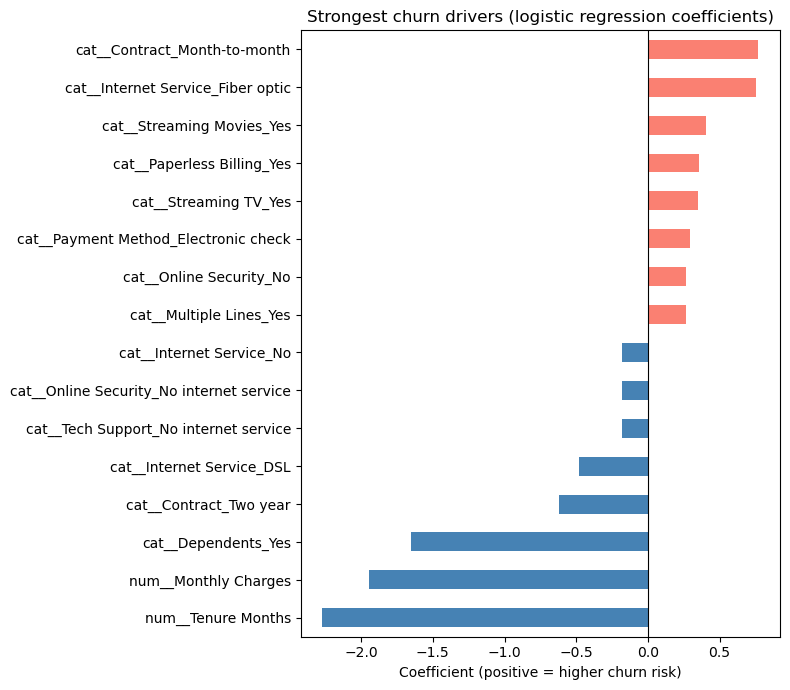

In [18]:
feature_names = best_model.named_steps['prep'].get_feature_names_out()
coefs = pd.Series(best_model.named_steps['model'].coef_[0], index=feature_names)
coefs = coefs[coefs != 0].sort_values()

top = pd.concat([coefs.head(8), coefs.tail(8)])
plt.figure(figsize=(8, 7))
top.plot(kind='barh', color=['steelblue' if v < 0 else 'salmon' for v in top])
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Strongest churn drivers (logistic regression coefficients)')
plt.xlabel('Coefficient (positive = higher churn risk)')
plt.tight_layout()
plt.show()

### Conclusion on churn drivers

The model agrees with the chi-square results in Part C. Month-to-month contracts and fibre-optic internet are the strongest predictors of churn, followed by streaming services, paperless billing and paying by electronic check. Longer tenure, having dependents and two-year contracts reduce churn risk. Customers who are committed stay, so the main retention lever is moving month-to-month customers onto longer contracts.

**On Monthly Charges:** Its coefficient is negative even though churners pay more on average (Part A). This is because a customer's monthly bill is largely determined by the services they take, such as fibre, streaming and multiple lines, and those services are already in the model. So the coefficient describes the effect of a higher bill for the same set of services, while the effect of the expensive services themselves appears in their own positive coefficients.